### Импорты

In [230]:
import re
from collections import Counter
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

### Константы

In [181]:
ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'data'
TASK_1 = DATA_DIR / 'athlete_events.csv'
TASK_2 = DATA_DIR / 'telecom_churn.csv'
TASK_3_URL = 'https://en.wikipedia.org/wiki/List_of_Formula_One_World_Drivers%27_Champions'

### Задание №1

1.  Загрузите  данные  из  файла  «athlete_events.csv»  о  спортсменах  – участниках 
олимпийских игр (ОИ).

Данные содержат следующие признаки: 
- ID – уникальный идентификатор спортсмена 
- Name – имя спортсмена 
- Sex – пол (M – мужской, F – женский) 
- Age – возраст (полных лет, целое число) 
- Height – рост в сантиметрах 
- Weight – вес в килограммах 
- Team – название команды (страны) 
- NOC – трехбуквенное обозначение страны (по стандарту МОК) 
- Games – год и вид ОИ (летние или зимние) 
- Year – год проведения ОИ 
- Season – вид ОИ (летние или зимние) 
- City – город проведения ОИ 
- Sport – вид спорта 
- Event – соревнование (дисциплина) 
- Medal – завоеванная медаль (Gold, Silver, Bronze или NA) 

In [182]:
athlete_events = pd.read_csv(TASK_1)
athlete_events.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [183]:
athlete_events.info()

<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  str    
 2   Sex     271116 non-null  str    
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  str    
 7   NOC     271116 non-null  str    
 8   Games   271116 non-null  str    
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  str    
 11  City    271116 non-null  str    
 12  Sport   271116 non-null  str    
 13  Event   271116 non-null  str    
 14  Medal   39783 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 31.0 MB


2.  Определите количество значений каждого из признаков в загруженных данных. По каким значениям имеются не все данные? По какому значению отсутствующих данных больше всего?

Подсказка: воспользуйтесь функцией count или info. 

**Ответ:**

Не все данные имеются в столбцах: `Возраст (Age)`, `Рост (Height)`, `Вес (Weight)` и `Завоеванная медаль (Medal)`.

Больше всего данных отсутствуют в столбце `Завоеванная медаль (Medal)` - *231 333*.

In [184]:
print('Количество пропусков по столбцам:')
#athlete_events.count()
#athlete_events.info()
athlete_events.isna().sum()

Количество пропусков по столбцам:


ID             0
Name           0
Sex            0
Age         9474
Height     60171
Weight     62875
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     231333
dtype: int64

3. Выведите  статистическую  информацию  (среднее  значение,  стандартное отклонение, минимальное и максимальное значение, значение квартилей) по полям: возраст, рост, вес.

Подсказка: воспользуйтесь функцией describe. 

In [185]:
cols_3 = ['Age', 'Height', 'Weight']
athlete_events[cols_3].describe()

,Age,Height,Weight
count,261642.000000,210945.000000,208241.000000
mean,25.556898,175.338970,70.702393
std,6.393561,10.518462,14.348020
min,10.000000,127.000000,25.000000
25%,21.000000,168.000000,60.000000
50%,24.000000,175.000000,70.000000
75%,28.000000,183.000000,79.000000
max,97.000000,226.000000,214.000000


4.  Ответьте на вопросы, написав соответствующий код

- 1)  Сколько лет было самому молодому участнику олимпийских игр в 1992 
году? Как звали этого участника и в какой дисциплине он(а) участвовал(а)?

**Ответ:**

Самому молодому участнику олимпийских игр 1992 было `11` лет.

`Carlos Bienvenido Front Barrera` учавствовал в дисциплине `Rowing Men's Coxed Eights`.

In [186]:
year_1992_filt = athlete_events['Year'] == 1992
idx_min_age_1992 = athlete_events[year_1992_filt]['Age'].idxmin()
athlete_events.iloc[idx_min_age_1992]

ID                                  37333
Name      Carlos Bienvenido Front Barrera
Sex                                     M
Age                                  11.0
Height                                NaN
Weight                                NaN
Team                                Spain
NOC                                   ESP
Games                         1992 Summer
Year                                 1992
Season                             Summer
City                            Barcelona
Sport                              Rowing
Event           Rowing Men's Coxed Eights
Medal                                 NaN
Name: 73461, dtype: object

- 2)  Выведите  список  всех  видов  спорта,  которые  когда-либо  входили  в программу олимпийских игр. (Каждый вид спорта должен присутствовать в списке один раз.)

In [187]:
athlete_events['Sport'].unique()

<StringArray>
[               'Basketball',                      'Judo',
                  'Football',                'Tug-Of-War',
             'Speed Skating',      'Cross Country Skiing',
                 'Athletics',                'Ice Hockey',
                  'Swimming',                 'Badminton',
                   'Sailing',                  'Biathlon',
                'Gymnastics',          'Art Competitions',
             'Alpine Skiing',                  'Handball',
             'Weightlifting',                 'Wrestling',
                      'Luge',                'Water Polo',
                    'Hockey',                    'Rowing',
                 'Bobsleigh',                   'Fencing',
             'Equestrianism',                  'Shooting',
                    'Boxing',                 'Taekwondo',
                   'Cycling',                    'Diving',
                  'Canoeing',                    'Tennis',
         'Modern Pentathlon',            '

- 3)  Каков средний рост теннисисток (пол –  женский, вид спорта –  большой теннис), участвовавших в играх 2000 года?

**Ответ:**

Средний рост теннисисток в играх 2000 года составил `171.792` сантиметра.

In [188]:
query_4_3 = 'Sex=="F" and Sport=="Tennis" and Year==2000'
athlete_events.query(query_4_3)['Height'].mean()

np.float64(171.792)

- 4)  Сколько золотых медалей в настольном теннисе выиграл Китай на ОИ в 2008 году?

**Ответ:**

За 2008 год Китайские команды заработали `74` золотые медали

In [189]:
filt_team_4_4 = athlete_events['Team'].str.contains('china', case=False, na=False)
#filt_team_4_4 = athlete_events['Team'] == 'CHN'
filt_medal_4_4 = athlete_events['Medal'] == 'Gold'
filt_year_4_4 = athlete_events['Year'] == 2008
filt_4_4 = filt_team_4_4 & filt_medal_4_4 & filt_year_4_4
filt_4_4.sum()

np.int64(74)

- 5)  Как изменилось количество видов спорта на летних ОИ в 2004 году по сравнению с летними ОИ в 1988 году?

**Ответ:**

По сравнению с летними ОИ в 1988 году (видов спорта: 27), в 2004 году на летних ОИ (видов спорта: 34) добавилось `7` видов спорта.

In [190]:
filt_season_4_5 = athlete_events['Season'] == 'Summer'
filt_year_1988 = athlete_events['Year'] == 1988
filt_year_2004 = athlete_events['Year'] == 2004
count_sport_2004, = athlete_events[filt_season_4_5 & filt_year_2004]['Sport'].unique().shape
count_sport_1988, = athlete_events[filt_season_4_5 & filt_year_1988]['Sport'].unique().shape
diff_2004_1988 = count_sport_2004 - count_sport_1988

print(f'Кол-во видов спорта в 2004: {count_sport_2004}, кол-во видов сопрта в 1988: {count_sport_1988}.\nРазница составила: {diff_2004_1988}')

Кол-во видов спорта в 2004: 34, кол-во видов сопрта в 1988: 27.
Разница составила: 7


- 6)  Постройте  гистограмму  распределения  возраста  мужчин-керлингистов (Sport  == ‘Curling’), участвовавших в олимпиаде 2014 года. 

Подсказка: для построения  гистограммы  можно  использовать  функцию  hist() из библиотеки  matplotlib с  параметрами  по  умолчанию  (либо  можете использовать любую другую функцию на свое усмотрение).

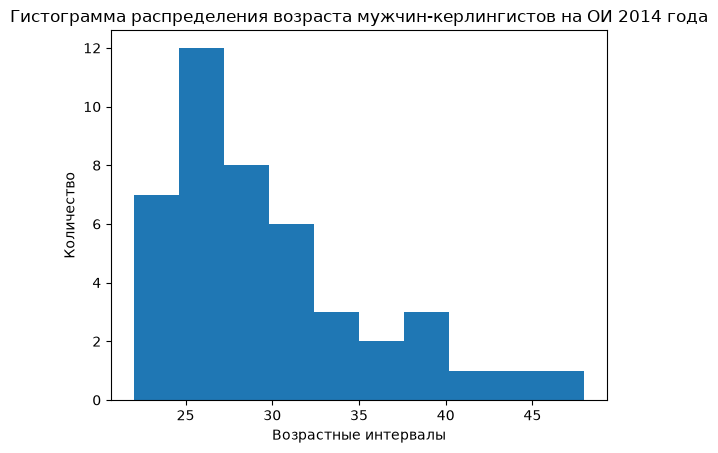

In [191]:
query_4_6 = 'Sport=="Curling" and Year==2014 and Sex=="M"'

plt.hist(athlete_events.query(query_4_6)['Age'].dropna())
plt.title('Гистограмма распределения возраста мужчин-керлингистов на ОИ 2014 года')
plt.xlabel('Возрастные интервалы')
plt.ylabel('Количество')
plt.show()

- 7)   Рассмотрим зимнюю олимпиаду 2006 года. Сгруппируйте данные по стране (используйте признак «NOC») и посчитайте для каждой страны количество завоеванных медалей и средний возраст спортсменов. Выведите только те страны, которые завоевали хотя бы одну медаль.

In [192]:
filt_year_4_7 = athlete_events['Year'] == 2006
filt_season_4_7 = athlete_events['Season'] == 'Winter'
filt_medal_4_7 = athlete_events['Medal'].notna()
filt_4_7 = filt_year_4_7 & filt_season_4_7 & filt_medal_4_7
athlete_events[filt_4_7].groupby('NOC').agg(count_meadals=('Medal', 'count'), mean_age=('Age', 'mean'))

,count_meadals,mean_age
NOC,,
AUS,2,26.000000
AUT,30,27.333333
BLR,1,28.000000
BUL,1,28.000000
CAN,69,27.449275
CHN,13,24.461538
CRO,3,24.666667
CZE,27,29.814815
EST,3,30.333333


- 8)  Продолжим  рассматривать  зимнюю  олимпиаду  2006  года.  Посчитайте, сколько медалей каждого достоинства завоевала каждая из стран-участниц (страны, не завоевавшие ни одной медали, можно не выводить). Для этого сгруппируйте данные по стране и по виду медали. Представьте данные в виде сводной таблицы (pivot_table). В сводной таблице не должно быть отсутствующих значений (NaN), замените их на 0.

In [193]:
#athlete_events[filt_4_7].groupby(['NOC', 'Medal']).agg(count=('Medal', 'count')).unstack(fill_value=0)
athlete_events[filt_4_7].pivot_table(index='NOC', columns='Medal', aggfunc='size', fill_value=0)

Medal,Bronze,Gold,Silver
NOC,,,
AUS,1,1,0
AUT,7,16,7
BLR,0,0,1
BUL,0,0,1
CAN,11,30,28
CHN,6,2,5
CRO,0,1,2
CZE,24,1,2
EST,0,3,0


### Задание №2

Загрузите данные из файла «telecom_churn.csv» о клиентах оператора сотовой связи.

Данные содержат, в числе прочих, следующие признаки: 
- State – обозначение территории (штата) 
- Area code – код города 
- International plan – подключена ли услуга международного роуминга 
- Number vmail messages – количество голосовых сообщений 
- Total day minutes – суммарная продолжительность дневных звонков (в минутах) 
- Total day calls – количество дневных звонков 
- Total eve minutes, Total eve calls – аналогичные показатели по вечерним звонкам 
- Total night minutes, Total night calls – аналогично по ночным звонкам 
- Customer service calls – количество звонков в службу поддержки 
- Churn  –  отток клиентов (False  –  клиент активен, True  –  клиент потерян, то есть расторг договор) 

Остальные столбцы можно сразу проигнорировать при загрузке данных. 

In [194]:
usecols = ['State', 'Area code', 'International plan', 'Number vmail messages', 'Total day minutes', 'Total day calls',
           'Total eve minutes', 'Total eve calls', 'Total night minutes', 'Total night calls', 'Customer service calls', 'Churn']
telecom_churn = pd.read_csv(TASK_2, usecols=usecols)
telecom_churn.head(5)

,State,Area code,International plan,Number vmail messages,Total day minutes,Total day calls,Total eve minutes,Total eve calls,Total night minutes,Total night calls,Customer service calls,Churn
0,KS,415,No,25,265.1,110,197.4,99,244.7,91,1,False
1,OH,415,No,26,161.6,123,195.5,103,254.4,103,1,False
2,NJ,415,No,0,243.4,114,121.2,110,162.6,104,0,False
3,OH,408,Yes,0,299.4,71,61.9,88,196.9,89,2,False
4,OK,415,Yes,0,166.7,113,148.3,122,186.9,121,3,False


1.  Выведите общую информацию о датафрейме с помощью методов info или describe. Есть ли отсутствующие данные?

**Ответ:**

В данных отсутствуют пропущенные значения.

In [195]:
telecom_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   str    
 1   Area code               3333 non-null   int64  
 2   International plan      3333 non-null   str    
 3   Number vmail messages   3333 non-null   int64  
 4   Total day minutes       3333 non-null   float64
 5   Total day calls         3333 non-null   int64  
 6   Total eve minutes       3333 non-null   float64
 7   Total eve calls         3333 non-null   int64  
 8   Total night minutes     3333 non-null   float64
 9   Total night calls       3333 non-null   int64  
 10  Customer service calls  3333 non-null   int64  
 11  Churn                   3333 non-null   bool   
dtypes: bool(1), float64(3), int64(6), str(2)
memory usage: 289.8 KB


2.  С помощью метода value_counts определите, сколько клиентов активны, а сколько потеряно. Сколько процентов клиентов в имеющихся данных активны, а сколько потеряны?

**Ответ:**

`2850` клиентов активны (`85.51%`), `483` клиента потеряно (`14.49%`).

In [196]:
counts = telecom_churn['Churn'].value_counts()
percents = telecom_churn['Churn'].value_counts(normalize=True) * 100
pd.DataFrame({
    'Количество': counts,
    'Процент %': percents.round(2)
})

,Количество,Процент %
Churn,,
False,2850,85.51
True,483,14.49


3.  Добавьте дополнительный столбец в датафрейм – средняя продолжительность одного  звонка  (вычислить  как  суммарная  продолжительность  всех  звонков, деленная на суммарное количество всех звонков). Отсортируйте данные по этому значению по убыванию и выведите 10 первых записей. 

In [197]:
sum_minutes = telecom_churn['Total day minutes'] + telecom_churn['Total eve minutes'] + telecom_churn['Total night minutes']
sum_calls = telecom_churn['Total day calls'] + telecom_churn['Total eve calls'] + telecom_churn['Total night calls']
telecom_churn['Average duration of a single call'] = sum_minutes / sum_calls
sorted_telecom_churn = telecom_churn.sort_values('Average duration of a single call', ascending=False)
sorted_telecom_churn.head(10)

,State,Area code,International plan,Number vmail messages,Total day minutes,Total day calls,Total eve minutes,Total eve calls,Total night minutes,Total night calls,Customer service calls,Churn,Average duration of a single call
985,NY,415,Yes,0,346.8,55,249.5,79,275.4,102,1,True,3.693644
2824,OR,415,No,0,324.7,48,236.4,82,187.6,78,0,True,3.599519
244,VA,408,No,0,198.5,99,267.8,60,354.9,75,0,True,3.509402
2321,AR,408,No,0,154.6,56,263.0,84,367.7,89,1,False,3.429258
2033,NJ,408,No,0,217.6,87,279.0,71,250.7,65,2,True,3.351121
1709,NV,408,No,0,197.7,68,250.5,53,181.2,67,3,False,3.347872
2536,CT,408,No,0,294.2,100,232.5,53,195.0,64,0,True,3.325806
1686,CT,408,No,40,231.9,56,211.8,91,268.5,74,2,False,3.222624
649,MO,408,No,0,261.7,97,210.6,48,256.7,83,3,True,3.197368
2289,MS,415,Yes,23,245.5,54,292.7,83,184.0,90,1,False,3.181498


4.  Сгруппируйте  данные  по  значению  поля  «Churn»  и  вычислите  среднюю продолжительность одного звонка в каждой категории. Есть ли существенная разница  в  средней продолжительности одного звонка между активными и потерянными клиентами?

**Ответ:**

Разница между активными и потерянными клиентами несущественна - `0.153`.

In [198]:
telecom_churn.groupby('Churn').agg(avg_duration=('Average duration of a single call', 'mean'))

,avg_duration
Churn,
False,1.938102
True,2.091193


5.  Сгруппируйте данные по значению поля «Churn» и вычислите среднее количество звонков в службу поддержки в каждой категории. Есть ли существенная разница между активными и потерянными клиентами?

**Ответ:**

В отличии от предыдущего показателя, данный показатель имеет существенную разницу между категориями.

Средний клиент, который расторг договор, существенно больше раз обращался в службу поддержки. Разница составила приблизительно `0.779`.

In [199]:
telecom_churn.groupby('Churn').agg(avg_duration=('Customer service calls', 'mean'))

,avg_duration
Churn,
False,1.449825
True,2.229814


6.  Исследуйте подробнее связь между параметрами «Churn» и «Customer service calls», построив  таблицу  сопряженности  (факторную  таблицу)  по  этим  признакам.

Подсказка:  используйте  функцию  crosstab.  При  каком  количестве  звонков  в службу поддержки процент оттока становится существенно выше, чем в целом по датафрейму? (В качестве уточнения  фразы  «существенно  выше»  можете использовать «более 40%».)

**Ответ:**

Из полученного ранее процентного соотношения следует, что процент оттока по всему набору составляет `14.5%`.

Более 40% разницы наблюдается у количества звонков: `5`, `6`, `7` и `9`. 

In [200]:
crosstab = pd.crosstab(telecom_churn['Churn'], telecom_churn['Customer service calls'], normalize='columns') * 100
crosstab.round(2)

Customer service calls,0,1,2,3,4,5,6,7,8,9
Churn,,,,,,,,,,
False,86.8,89.67,88.54,89.74,54.22,39.39,36.36,44.44,50.0,0.0
True,13.2,10.33,11.46,10.26,45.78,60.61,63.64,55.56,50.0,100.0


7.  Аналогично предыдущему пункту исследуйте связь между параметрами «Churn» и «International  plan». Можно ли утверждать, что процент оттока среди клиентов, использующих международный роуминг, существенно выше или ниже, чем среди клиентов, не использующих его?

**Ответ:**

Клиенты, использующие международный роуминг значительно чаще отказываются от услуг оператора (`42.41%`) в сравнении с клиентами не пользующиеся им (`11.5%`).

In [201]:
crosstab = pd.crosstab(telecom_churn['Churn'], telecom_churn['International plan'], normalize='columns') * 100
crosstab.round(2)

International plan,No,Yes
Churn,,
False,88.5,57.59
True,11.5,42.41


8.  Добавьте в датафрейм столбец «Прогнозируемый отток», заполнив его на основе значений  столбцов  «Customer service calls»  и  «International plan». Сравните значение  в  этом столбце со  значением  столбца  «Churn».  Если  мы  будем пользоваться  построенным  прогнозом,  то  какой  процент  ошибок  первого  и второго рода (ложноположительных и ложноотрицательных) мы получим? 

**Ответ:**

При использовании нижеописанного подхода на основе правил,

ошибка первого рода - `0.32%`,

ошибка второго рода - `96.07%`.

Правило практически не прогнозирует отток у клиентов, которые в действительности остаются, но пропускает большую часть клиентов, которые действительно уходят.

In [202]:
customer_service_calls_rule = telecom_churn['Customer service calls'] > 3
international_plan_rule = telecom_churn['International plan'] == 'Yes'
rules = customer_service_calls_rule & international_plan_rule
telecom_churn['Prediction churn'] = rules

In [203]:
pd.crosstab(telecom_churn['Churn'], telecom_churn['Prediction churn'])

Prediction churn,False,True
Churn,,
False,2841,9
True,464,19


In [204]:
y_pred = telecom_churn['Prediction churn']
y = telecom_churn['Churn']

fp = ((y_pred == True) & (y == False)).sum()
tn = ((y_pred == False) & (y == False)).sum()
fn = ((y_pred == False) & (y == True)).sum()
tp = ((y_pred == True) & (y == True)).sum()

error_type_1 = fp / (fp + tn) * 100
error_type_2 = fn / (fn + tp) * 100

print(f'Ошибка первого рода: {error_type_1:.2f}%')
print(f'Ошибка второго рода: {error_type_2:.2f}%')

Ошибка первого рода: 0.32%
Ошибка второго рода: 96.07%


### Задание №3

1.  Загрузите  данные  о  чемпионах  автогонок  «Формула  1» с  сайта https://en.wikipedia.org/wiki/List_of_Formula_One_World_Drivers%27_Champions (используйте таблицу с указанием всех чемпионов по годам)

In [205]:
headers = {
    "User-Agent": "Mozilla/5.0 (compatible; PandasStudent/1.0)"
}

response = requests.get(
    TASK_3_URL,
    headers=headers,
    timeout=30
)
response.raise_for_status()

In [206]:
f1_champions = pd.read_html(StringIO(response.text))

In [207]:
for i, table in enumerate(f1_champions):
    print(f"\nТаблица {i}")
    print(table.shape)
    print(table.columns.tolist())


Таблица 0
(8, 1)
[0]

Таблица 1
(1, 2)
[0, 1]

Таблица 2
(80, 16)
[('Season', 'Season'), ('Driver', 'Driver'), ('Age', 'Age'), ('Constructor', 'Chassis'), ('Constructor', 'Engine'), ('Tyres', 'Tyres'), ('Poles', 'Poles'), ('Wins', 'Wins'), ('Podiums', 'Podiums'), ('Fastest laps', 'Fastest laps'), ('Points', 'Points'), ('% Points', '% Points'), ('Clinched[17]', 'Clinched[17]'), ('# of rounds remaining', '# of rounds remaining'), ('Margin', 'Margin'), ('% Margin', '% Margin')]

Таблица 3
(36, 3)
['Driver', 'Titles', 'Season(s)']

Таблица 4
(36, 5)
['Country', 'Titles', 'Drivers', 'Seasons', 'By driver (titles)']

Таблица 5
(10, 4)
['Unnamed: 0', 'Driver', 'Age', 'Season']

Таблица 6
(10, 4)
['Unnamed: 0', 'Driver', 'Age', 'Season']

Таблица 7
(13, 3)
['Championships', 'Driver', 'Seasons']

Таблица 8
(10, 3)
['Championships', 'Drivers[a]', 'Years']

Таблица 9
(17, 3)
['Constructor', 'Titles', 'Season(s)']

Таблица 10
(15, 3)
['Manufacturer', 'Titles', 'Season(s)']

Таблица 11
(8, 5)
['Ra

In [208]:
f1_champions_by_season = f1_champions[2]

2.  Посмотрите  результат  загрузки,  при  необходимости  удалите  лишние  строки (подсказка: «подвал» таблицы, то есть последние несколько строк, не нужны).

- Season — год проведения сезона Формулы-1.
- Driver — имя пилота, ставшего чемпионом мира в соответствующем сезоне.
- Age — возраст чемпиона на момент завоевания титула.
- Constructor Chassis — название команды или производителя шасси, на котором выступал чемпион.
- Constructor Engine — производитель или название двигателя, использовавшегося в чемпионском болиде.
- Tyres — производитель шин, на которых выступал чемпион.
- Poles — количество поул-позиций, завоёванных пилотом за сезон.
- Wins — количество побед в гонках за сезон.
- Podiums — количество финишей на подиуме (1-е, 2-е или 3-е место).
- Fastest laps — количество самых быстрых кругов, показанных пилотом за сезон.
- Points — количество очков, набранных пилотом за сезон.
- % Points — доля набранных очков от максимально возможного количества очков.
- Clinched — этап сезона, на котором пилот досрочно или по итогам последней гонки обеспечил себе чемпионский титул.
- #of rounds remaining — количество гонок, оставшихся до конца сезона на момент завоевания титула.
- Margin — разница в очках между чемпионом и пилотом, занявшим второе место в чемпионате.
- % Margin — преимущество чемпиона над ближайшим соперником в процентном выражении.

In [209]:
f1_champions_by_season.head()

Season                  Driver Age Constructor             Tyres Poles  \
    Season                  Driver Age     Chassis      Engine Tyres Poles   
0     1950     Giuseppe Farina[23]  44  Alfa Romeo  Alfa Romeo     P     2   
1     1951  Juan Manuel Fangio[24]  40  Alfa Romeo  Alfa Romeo     P     4   
2  1952[a]      Alberto Ascari[26]  34     Ferrari     Ferrari   F P     5   
3  1953[a]      Alberto Ascari[26]  35     Ferrari     Ferrari     P     6   
4     1954  Juan Manuel Fangio[24]  43    Maserati    Maserati     P     5   

  Wins Podiums Fastest laps Points          % Points  Clinched[17]  \
  Wins Podiums Fastest laps Points          % Points  Clinched[17]   
0    3       3            3     30   83.333 (47.619)  Round 7 of 7   
1    3       5            5     31   86.111 (51.389)  Round 8 of 8   
2    6       6            6     36  100.000 (74.306)  Round 6 of 8   
3    5       5            4   34.5   95.833 (57.407)  Round 8 of 9   
4    6       7            3     42   93.333 (70.547)  Round 7 of 9   

  # of rounds remaining  Margin % Margin  
  # of rounds remaining  Margin % Margin  
0                     0       3   10.000  
1                     0       6   19.355  
2                     2      12   33.333  
3                     1     6.5   18.841  
4                     2  16.857   40.136

In [210]:
f1_champions_by_season.tail()

Season              Driver  Age  Constructor               Tyres  Poles  \
    Season              Driver  Age      Chassis       Engine  Tyres  Poles   
75    2024  Max Verstappen[60]   27     Red Bull   Honda RBPT      P      8   
76     NaN                 NaN  NaN          NaN          NaN    NaN    NaN   
77    2025    Lando Norris[61]   26      McLaren     Mercedes      P      7   
78  Season              Driver  Age      Chassis       Engine  Tyres  Poles   
79  Season              Driver  Age  Constructor  Constructor  Tyres  Poles   

    Wins  Podiums  Fastest laps  Points  % Points    Clinched[17]  \
    Wins  Podiums  Fastest laps  Points  % Points    Clinched[17]   
75     9       14             3     437    65.030  Round 22 of 24   
76   NaN      NaN           NaN     NaN       NaN             NaN   
77     7       18             6     423    65.278  Round 24 of 24   
78  Wins  Podiums  Fastest laps  Points  % Points        Clinched   
79  Wins  Podiums  Fastest laps  Points  % Points        Clinched   

    # of rounds remaining  Margin  % Margin  
    # of rounds remaining  Margin  % Margin  
75                      2      63    14.416  
76                    NaN     NaN       NaN  
77                      0       2     0.473  
78  # of rounds remaining  Margin  % Margin  
79  # of rounds remaining  Margin  % Margin

In [211]:
f1_champions_by_season = f1_champions_by_season.iloc[:-2].dropna(how='all').reset_index(drop=True)

In [212]:
f1_champions_by_season.head()

Season                  Driver Age Constructor             Tyres Poles  \
    Season                  Driver Age     Chassis      Engine Tyres Poles   
0     1950     Giuseppe Farina[23]  44  Alfa Romeo  Alfa Romeo     P     2   
1     1951  Juan Manuel Fangio[24]  40  Alfa Romeo  Alfa Romeo     P     4   
2  1952[a]      Alberto Ascari[26]  34     Ferrari     Ferrari   F P     5   
3  1953[a]      Alberto Ascari[26]  35     Ferrari     Ferrari     P     6   
4     1954  Juan Manuel Fangio[24]  43    Maserati    Maserati     P     5   

  Wins Podiums Fastest laps Points          % Points  Clinched[17]  \
  Wins Podiums Fastest laps Points          % Points  Clinched[17]   
0    3       3            3     30   83.333 (47.619)  Round 7 of 7   
1    3       5            5     31   86.111 (51.389)  Round 8 of 8   
2    6       6            6     36  100.000 (74.306)  Round 6 of 8   
3    5       5            4   34.5   95.833 (57.407)  Round 8 of 9   
4    6       7            3     42   93.333 (70.547)  Round 7 of 9   

  # of rounds remaining  Margin % Margin  
  # of rounds remaining  Margin % Margin  
0                     0       3   10.000  
1                     0       6   19.355  
2                     2      12   33.333  
3                     1     6.5   18.841  
4                     2  16.857   40.136

In [213]:
f1_champions_by_season.tail()

Season              Driver Age Constructor             Tyres Poles Wins  \
   Season              Driver Age     Chassis      Engine Tyres Poles Wins   
72   2021  Max Verstappen[58]  24    Red Bull       Honda     P    10   10   
73   2022  Max Verstappen[58]  25    Red Bull        RBPT     P     7   15   
74   2023  Max Verstappen[59]  26    Red Bull  Honda RBPT     P    12   19   
75   2024  Max Verstappen[60]  27    Red Bull  Honda RBPT     P     8    9   
76   2025    Lando Norris[61]  26     McLaren    Mercedes     P     7    7   

   Podiums Fastest laps Points % Points    Clinched[17] # of rounds remaining  \
   Podiums Fastest laps Points % Points    Clinched[17] # of rounds remaining   
72      18            6  395.5   69.692  Round 22 of 22                     0   
73      17            5    454   76.174  Round 18 of 22                     4   
74      21            9    575   92.742  Round 17 of 22                     5   
75      14            3    437   65.030  Round 22 of 24                     2   
76      18            6    423   65.278  Round 24 of 24                     0   

   Margin % Margin  
   Margin % Margin  
72      8    2.023  
73    146   32.159  
74    290   50.435  
75     63   14.416  
76      2    0.473

3.  Проверьте тип данных.  Преобразуйте числовые  данные (возраст, число поулов, побед, подиумов, быстрейших кругов, очки и т.д.) к числовому типу. 

In [214]:
def remove_link_characters(s: str) -> str:
    return re.sub(r'\[[^\]]*\]', '', s)

In [215]:
new_cols_name = np.array([
    remove_link_characters(name_1 if name_1 == name_2 else f'{name_1} {name_2}')
    for name_1, name_2 in f1_champions_by_season.columns
])
new_cols_name

array(['Season', 'Driver', 'Age', 'Constructor Chassis',
       'Constructor Engine', 'Tyres', 'Poles', 'Wins', 'Podiums',
       'Fastest laps', 'Points', '% Points', 'Clinched',
       '# of rounds remaining', 'Margin', '% Margin'], dtype='<U21')

In [216]:
f1_champions_by_season = f1_champions_by_season.set_axis(new_cols_name, axis=1)

In [217]:
f1_champions_by_season.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Season                 77 non-null     str  
 1   Driver                 77 non-null     str  
 2   Age                    77 non-null     str  
 3   Constructor Chassis    77 non-null     str  
 4   Constructor Engine     77 non-null     str  
 5   Tyres                  77 non-null     str  
 6   Poles                  77 non-null     str  
 7   Wins                   77 non-null     str  
 8   Podiums                77 non-null     str  
 9   Fastest laps           77 non-null     str  
 10  Points                 77 non-null     str  
 11  % Points               77 non-null     str  
 12  Clinched               77 non-null     str  
 13  # of rounds remaining  77 non-null     str  
 14  Margin                 77 non-null     str  
 15  % Margin               77 non-null     str  
dtypes: 

In [218]:
for col in f1_champions_by_season.columns:
    f1_champions_by_season[col] = f1_champions_by_season[col].apply(remove_link_characters)

In [219]:
splited_clinched = f1_champions_by_season['Clinched'].str.strip().str.split()
f1_champions_by_season['Clinched_1'], f1_champions_by_season['Clinched_2'] = splited_clinched.str[1], splited_clinched.str[3]

In [220]:
int_cols = ['Season', 'Age', 'Poles', 'Wins', 'Podiums', 'Fastest laps', '# of rounds remaining', 'Clinched_1', 'Clinched_2']
float_cols = ['Points', 'Margin', '% Margin']

f1_champions_by_season[int_cols] = f1_champions_by_season[int_cols].astype(int)
f1_champions_by_season[float_cols] = f1_champions_by_season[float_cols].astype(float)

In [221]:
f1_champions_by_season.info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Season                 77 non-null     int64  
 1   Driver                 77 non-null     str    
 2   Age                    77 non-null     int64  
 3   Constructor Chassis    77 non-null     str    
 4   Constructor Engine     77 non-null     str    
 5   Tyres                  77 non-null     str    
 6   Poles                  77 non-null     int64  
 7   Wins                   77 non-null     int64  
 8   Podiums                77 non-null     int64  
 9   Fastest laps           77 non-null     int64  
 10  Points                 77 non-null     float64
 11  % Points               77 non-null     str    
 12  Clinched               77 non-null     str    
 13  # of rounds remaining  77 non-null     int64  
 14  Margin                 77 non-null     float64
 15  % Margin           

4.  Ответьте на вопросы, написав соответствующий код.

- 1)  Средний, минимальный  и  максимальный  возраст  гонщиков, становившихся чемпионами. 

In [222]:
pd.DataFrame({
    'Средний возраст': [f1_champions_by_season['Age'].mean()],
    'Минимальный возраст': [f1_champions_by_season['Age'].min()],
    'Максимальный возраст': [f1_champions_by_season['Age'].max()]
})

,Средний возраст,Минимальный возраст,Максимальный возраст
0,31.636364,23,46


- 2)  Гонщики какой команды выиграли больше всего личных титулов?  (Под командой в этом вопросе подразумевается конструктор шасси.)

**Ответ:**

Гонщики команды конструкторов шасси `Ferrari` выйграли больше всего личных титулов `15`.

In [223]:
f1_champions_by_season.groupby('Constructor Chassis').agg(count=('Constructor Chassis', 'count')).sort_values('count', ascending=False)

,count
Constructor Chassis,
Ferrari,15
McLaren,13
Mercedes,9
Red Bull,8
Williams,7
Lotus,6
Brabham,4
Alfa Romeo,2
Renault,2


- 3)  Имена гонщиков, наибольшее число раз становившихся чемпионами. 

In [224]:
f1_champions_by_season.groupby('Driver').agg(count=('Driver', 'count')).sort_values('count', ascending=False)

,count
Driver,
Lewis Hamilton,7
Michael Schumacher,7
Juan Manuel Fangio,6
Sebastian Vettel,4
Max Verstappen,4
Alain Prost,4
Niki Lauda,3
Nelson Piquet,3
Ayrton Senna,3


- 4)  Кто из гонщиков смог стать чемпионом, выиграв менее 30% гонок в сезоне? (Подсказка: число гонок в сезоне можно определить по столбцу, где указано в какой гонке из скольки был завоеван титул.)

In [225]:
filt = (f1_champions_by_season['Wins'] / f1_champions_by_season['Clinched_2']) < 0.3
f1_champions_by_season[filt][['Driver', 'Wins', 'Clinched']]

,Driver,Wins,Clinched
9,Mike Hawthorn,1,Round 11 of 11
10,Jack Brabham,2,Round 9 of 9
12,Phil Hill,2,Round 7 of 8
15,John Surtees,2,Round 10 of 10
18,Denny Hulme,2,Round 11 of 11
19,Graham Hill,3,Round 12 of 12
25,Emerson Fittipaldi,3,Round 15 of 15
28,Niki Lauda,3,Round 15 of 17
30,Jody Scheckter,3,Round 13 of 15
32,Nelson Piquet,3,Round 15 of 15


- 5)  Рассмотрим гонщиков, которые становились чемпионами хотя бы дважды. Рассмотрим промежутки времени между их «соседними»  чемпионствами. Каков  максимальный  перерыв  между  двумя  последовательными чемпионствами  одного  и  того  же  гонщика? 

Например,  Нельсон  Пике становился чемпионом в 1981, 1983 и 1987 годах. Для него такие перерывы составляют 2 года (с 1981 до 1983) и 4 года (с 1983 до 1987), максимальный из них –  4 года. Вам нужно найти максимум среди всех гонщиков.  (В этом задании можно не ограничиваться только функциями библиотек, но и написать свой код на Python.)

In [254]:
def get_max_gap_between_championships() -> pd.DataFrame:
    drivers = f1_champions_by_season['Driver']
    seasons = f1_champions_by_season['Season']
    count_championships_drivers = Counter(drivers)
    drivers_champion_years = {driver: [] for driver in drivers if count_championships_drivers[driver] > 1}
    for i, driver in enumerate(drivers):
         if count_championships_drivers[driver] > 1:
            drivers_champion_years[driver].append(seasons[i])
    drivers_champion_max_gap = {}
    for driver, years in drivers_champion_years.items():
        max_gap = max((years[i] - years[i - 1] for i in range(1, len(years))), default=0)
        drivers_champion_max_gap[driver] = max_gap
    return pd.DataFrame({
        'Driver': drivers_champion_max_gap.keys(),
        'Max gap': drivers_champion_max_gap.values()
    }).sort_values('Max gap', ascending=False)

In [255]:
get_max_gap_between_championships()

,Driver,Max gap
7,Niki Lauda,7
3,Graham Hill,6
2,Jack Brabham,6
14,Lewis Hamilton,6
11,Michael Schumacher,5
8,Nelson Piquet,4
9,Alain Prost,4
0,Juan Manuel Fangio,3
6,Emerson Fittipaldi,2
4,Jim Clark,2
